
!!! CRITICAL ALERT: Link (A -> B) has suffered physical damage and failed !!!

         ACO ROUTING OPTIMIZATION RESULTS        
• Final Best Route Found : A -> C -> E -> F
• Final Delay After Rerouting: 12 ms
• Total Iterations Monitored : 50


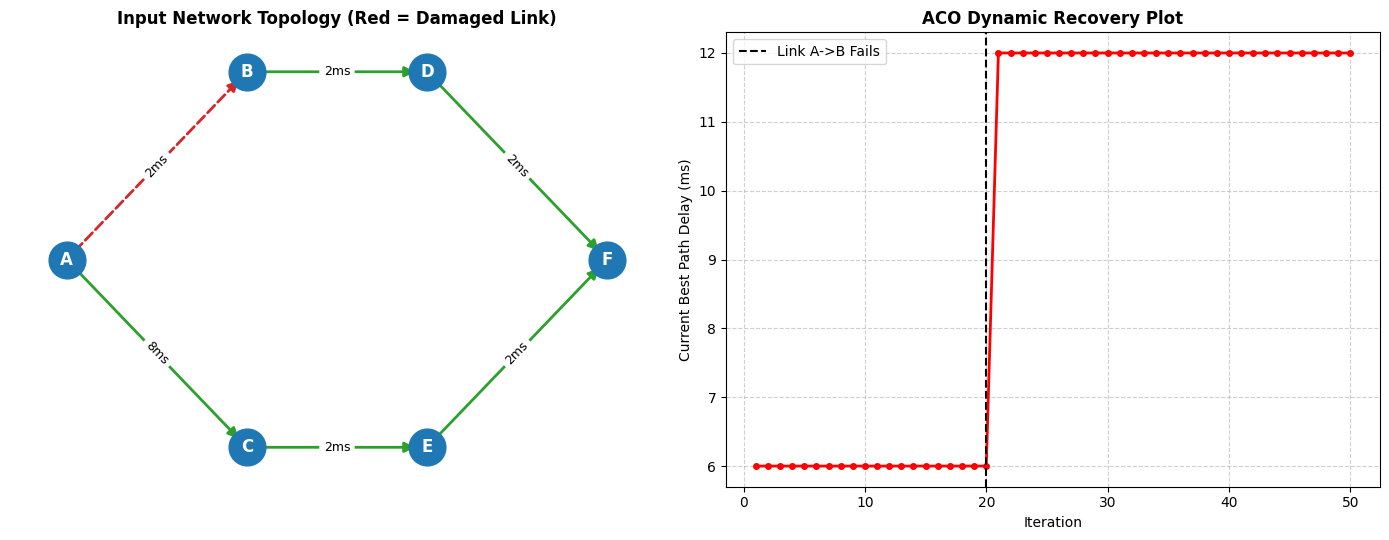

In [6]:
import random
import matplotlib.pyplot as plt
import networkx as nx

def aco_dynamic_network_routing():
    network = {
        'A': [('B', 2), ('C', 8)],
        'B': [('D', 2)],
        'C': [('E', 2)],
        'D': [('F', 2)],
        'E': [('F', 2)],
        'F': []
    }

    source = 'A'
    destination = 'F'

    NUM_ANTS = 20
    ITERATIONS = 50
    ALPHA = 1.0
    BETA = 2.0
    EVAPORATION = 0.2

    pheromones = {}
    for src_node in network:
        for dest_node, _ in network[src_node]:
            pheromones[(src_node, dest_node)] = 1.0

    convergence_history = []
    best_route_overall = None

    for iteration in range(ITERATIONS):
        if iteration == 20:
            print("\n!!! CRITICAL ALERT: Link (A -> B) has suffered physical damage and failed !!!\n")
            network['A'] = [('C', 8)]

        successful_tours = []
        min_delay_this_iteration = float('inf')
        best_route_this_iteration = None

        for ant in range(NUM_ANTS):
            current = source
            visited = [source]
            failed = False

            while current != destination:
                neighbors = network[current]
                allowed = [n for n in neighbors if n not in visited]

                if not allowed:
                    failed = True
                    break

                probabilities = []
                total_score = 0
                for neighbor, delay in allowed:
                    tau = pheromones.get((current, neighbor), 0.1) ** ALPHA
                    eta = (1.0 / delay) ** BETA
                    score = tau * eta
                    probabilities.append((neighbor, delay, score))
                    total_score += score

                pick = random.uniform(0, total_score)
                current_sum = 0
                for neighbor, delay, score in probabilities:
                    current_sum += score
                    if current_sum >= pick:
                        visited.append(neighbor)
                        current = neighbor
                        break

            if not failed:
                total_path_delay = 0
                for i in range(len(visited) - 1):
                    for neighbor, delay in network[visited[i]]:
                        if neighbor == visited[i+1]:
                            total_path_delay += delay

                successful_tours.append((visited, total_path_delay))
                if total_path_delay < min_delay_this_iteration:
                    min_delay_this_iteration = total_path_delay
                    best_route_this_iteration = visited

        for link in list(pheromones.keys()):
            pheromones[link] *= (1.0 - EVAPORATION)

        for path, delay in successful_tours:
            reward = 20.0 / delay
            for i in range(len(path) - 1):
                if (path[i], path[i+1]) in pheromones:
                    pheromones[(path[i], path[i+1])] += reward

        convergence_history.append(min_delay_this_iteration)
        best_route_overall = best_route_this_iteration

    print("=" * 45)
    print("         ACO ROUTING OPTIMIZATION RESULTS        ")
    print("=" * 45)
    route_str = " -> ".join(best_route_overall) if best_route_overall else "No path found"
    print(f"• Final Best Route Found : {route_str}")
    print(f"• Final Delay After Rerouting: {convergence_history[-1]} ms")
    print(f"• Total Iterations Monitored : {ITERATIONS}")
    print("=" * 45)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

    G = nx.DiGraph()
    initial_edges = [
        ('A', 'B', 2), ('A', 'C', 8), ('B', 'D', 2),
        ('C', 'E', 2), ('D', 'F', 2), ('E', 'F', 2)
    ]
    for u, v, w in initial_edges:
        G.add_edge(u, v, weight=w)

    pos = {'A': (0, 1), 'B': (1, 2), 'C': (1, 0), 'D': (2, 2), 'E': (2, 0), 'F': (3, 1)}

    edge_colors = []
    edge_styles = []
    for u, v in G.edges():
        if u == 'A' and v == 'B':
            edge_colors.append('#d62728')
            edge_styles.append('dashed')
        else:
            edge_colors.append('#2ca02c')
            edge_styles.append('solid')

    nx.draw_networkx_nodes(G, pos, ax=ax1, node_color='#1f77b4', node_size=700)
    nx.draw_networkx_labels(G, pos, ax=ax1, font_color='white', font_weight='bold')
    nx.draw_networkx_edges(G, pos, ax=ax1, edge_color=edge_colors, style=edge_styles, width=2, arrowsize=15)

    edge_labels = nx.get_edge_attributes(G, 'weight')
    edge_label_format = {k: f"{v}ms" for k, v in edge_labels.items()}
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_label_format, ax=ax1, font_size=9)

    ax1.set_title('Input Network Topology (Red = Damaged Link)', fontsize=12, fontweight='bold')
    ax1.axis('off')

    ax2.plot(range(1, ITERATIONS + 1), convergence_history, color='red', linewidth=2, marker='o', markersize=4)
    ax2.axvline(x=20, color='black', linestyle='--', linewidth=1.5, label='Link A->B Fails')
    ax2.set_title('ACO Dynamic Recovery Plot', fontsize=12, fontweight='bold')
    ax2.set_xlabel('Iteration')
    ax2.set_ylabel('Current Best Path Delay (ms)')
    ax2.legend()
    ax2.grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()

aco_dynamic_network_routing()
